## **[실습 2] scikit-learn을 활용한 Linear Regression**

### **1. 데이터 생성하기**

**Q1. 200개의 0~30 사이의 랜덤한 데이터를 생성한다**

그리고 이 데이터를 X라는 변수에 저장한다.

- [HINT] : np.random.randint()

In [3]:
# code here
import numpy as np
import random 
# 랜덤 시드를 지정
np.random.seed(101)   # seed: 난수를 생성하기 위한 재료 -> 동일하게 맞춰주면 같은 난수가 생성
X = np.random.randint(0, 30, 200) # vector
print(X)

[11 17  6 23 29 11 15  9 13  8  4  8 21 28 28  0 14  5 12 29  8 17 19 15
 26  8 19 29 19 27  2 12  8 25 19 10 12 11 23  0  9 23  9 15  8  4 19  3
 28  7 10 20 24  7  6 14  9 20 18 23  7  7 15 12  0 20 10 12 17 24 11 19
 15  1 29 24  4 28 19 18  3 10 19 28  7 20 27  8 22 26 26 19 23 14 15 22
  5 22  9 29 13  2 18 26 15 28 11 27 10 17  3 28  3 19 20 15 14 26  5 25
 28  5 24 19  6 24  7 27  5 14  7  5  4 20 23  3 15  2  3 18 25 13 14  3
 14 28  5 22 29 22 21 26 21 17 23 11  4  7 20 27 11  5 17 22 25 18 13  6
  3 24 14 17 23 20 29 13 15 17 24 20  0 20 28 15 18 29 28 21 11  8 27 13
  1 24  4  6  9 29 20  3]


**Q2. X에 정규분포적 샘플을 더한다.**

그리고 이 데이터를 y라는 변수에 저장한다.
- [HINT] : np.random.normal()

In [4]:
# code here
y = X + np.random.normal(size=X.size)
print(y)

[11.11327468 15.5910635   6.66255193 22.80343852 29.32822664 12.18704033
 13.83630314  8.48774838 11.86217136  7.99565057  5.98128298  6.91161643
 19.82850808 28.39448434 27.19209014  1.07256604 14.17846516  4.45646499
 10.70026507 28.80195514  6.53716808 18.14830046 18.40644307 14.41174931
 25.26762566  7.35575772 18.3948608  27.91350575 20.10635226 27.26819141
  2.46348592 12.94466666  8.96743226 24.35820253 19.71567821 10.92421272
 11.54464802 11.50870511 24.68647604  0.95623213  9.14887505 20.97156085
  8.28513078 14.12766879  9.83675321  4.86278216 20.5068988   3.04927004
 28.81629894  5.39275847  9.19226899 18.90364645 23.2109161   8.28648614
  6.27413248 13.11951825 10.06604894 18.6050461  18.30473706 22.40441944
  7.10757648  7.45384715 14.24398101 10.88114066  1.82881495 19.27934618
  7.94760518 10.67457507 16.48118286 22.61207237 10.53323044 17.82590191
 14.92264071  2.36634542 30.24158911 21.08011347  4.54754718 28.29450636
 17.31829141 17.35636217  1.49521123  9.98158846 19

### **2. 데이터 시각화하기**

**Q1. X와 y를 scatterplot으로 시각화한다.**

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

# 운영체제에 맞춰 한글 폰트 지정 (Visual Studio 환경이면 'nt'인 Windows로 작동)
if os.name == 'nt':
    plt.rcParams['font.family'] = 'Malgun Gothic'
else:
    plt.rcParams['font.family'] = 'AppleGothic'

# 축의 음수(-) 기호가 깨지는 현상 방지x
plt.rcParams['axes.unicode_minus'] = False

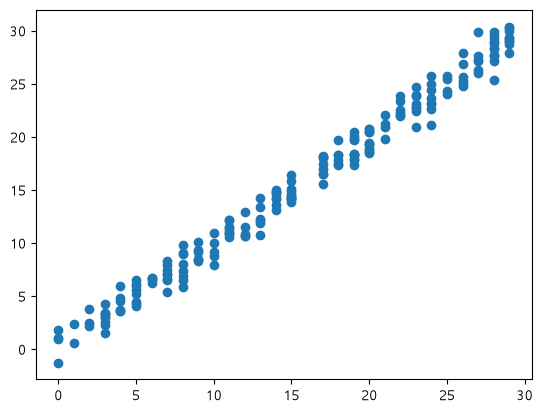

In [6]:
# code here
import matplotlib.pyplot as plt

plt.scatter(X, y)
plt.show()

### **3. Train, Test 데이터 분할하기**

**Q1.X와 y를 학습용 데이터와 테스트용 데이터로 분리한다.**
- 학습 : 테스트 데이터의 비율은 7 : 3 으로 한다.

**변수명은 다음과 같이 지정한다.**
- X_train : 학습 데이터의 특성
- X_test : 테스트 데이터의 특성
- y_train : 학습 데이터의 라벨
- y_test : 테스트 데이터의 라벨

In [7]:
# code here
# 학습, 테스트 데이터 분리를 하기 위해서는 
from sklearn.model_selection import train_test_split
# 데이터 뭉텅이 일부를 잘라서 반환
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)

In [8]:
print(X_train.size, X_test.size)
print(y_train.size, y_test.size)

140 60
140 60


### **4.Train과 Test 데이터 시각화하기**

**Q1.학습 데이터와 테스트 데이터를 다른 색상으로 scatterplot에 시각화해본다.**

test데이터는 test라는 라벨을 달아주고, train데이터는 train이라는 라벨을 달아준다.

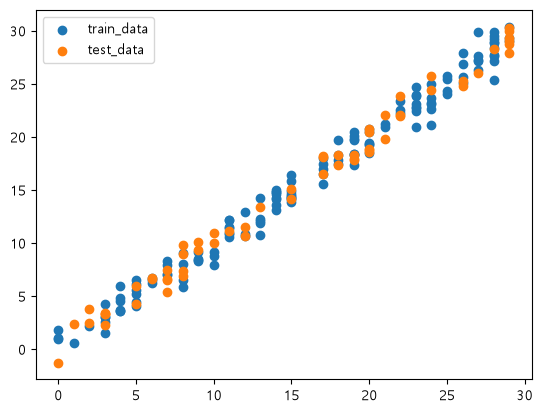

In [9]:
# code here
import matplotlib.pyplot as plt

plt.scatter(X_train, y_train, label = "train_data")
plt.scatter(X_test, y_test, label="test_data")
plt.legend()
plt.show()


### **5. 모델 생성, 학습**

**Q1. scikit-learn의 LinearRegression() 모델을 사용해서 학습 데이터로 학습시킨다.**

[HINT] : 현재 데이터가 scikit-learn의 모델이 학습하지 못하는 형태일 것이다 (1차원)
  - 에러 메세지를 잘 읽어보면 답이 나온다.

In [ ]:
# code here
# 1.우리의 모델을 불러와주기
from sklearn.linear_model import LinearRegression

# 모델 생성
# sklearn의 모든 모델들도 다 같은 명령어를 가진다
# fit(), predict()
model = LinearRegression()



**Q2. Linear Regression 모델이 학습한 coefficient와 intercept를 출력한다.**

In [ ]:
# 모든 머신러닝 모델은 matrix 형태의 input을 원함.
X_train = X_train.reshape(-1, 1)
print(X_train.shape, X_train.ndim)
print(X_train[:10])

(140, 1) 2
[[ 4]
 [ 5]
 [19]
 [24]
 [ 3]
 [17]
 [17]
 [14]
 [14]
 [25]]


In [16]:
# code here
model.fit(X_train, y_train)

print(model.coef_)
print(model.intercept_)

[0.99951559]
0.04770007913491092


### **6. 모델 테스트**

**Q1. 학습된 모델을 활용하여 테스트 데이터에 대한 예측 결과를 낸다.**

결과는 y_pred라는 변수에 저장한다.

In [17]:
# code here
# 테스트 데이터를 넣고 평가
y_pred = model.predict(X_test.reshape(-1, 1))

**Q2. 모델을 테스트 데이터를 활용해서 테스트한다.**

MAE, MSE, RMSE, 그리고 R2-score를 구하고, 출력해본다.

In [24]:
# code here
# sklearn의 모든 평가 지표는
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

print(f"MAE: {mean_absolute_error(y_test , y_pred)}")
print(f"MSE: {mean_squared_error(y_test, y_pred)}")
print(f"RMSE: {root_mean_squared_error(y_test, y_pred)}")
print(f"R2_score: {r2_score(y_test, y_pred)}")

MAE: 0.7948415457189084
MSE: 0.8669515281349711
RMSE: 0.9311023188323457
R2_score: 0.9886413585889486


### **7. Line of Best Fit 시각화하기**

**Q1. Line of Best Fit을 위의 scatterplot에 그려보자.**
- Line of Best Fit은 빨간색 파선으로, label="Line of Best Fit"이라고 작성한다.
- 그래프의 title을 "Linear Regression"으로 설정한다.

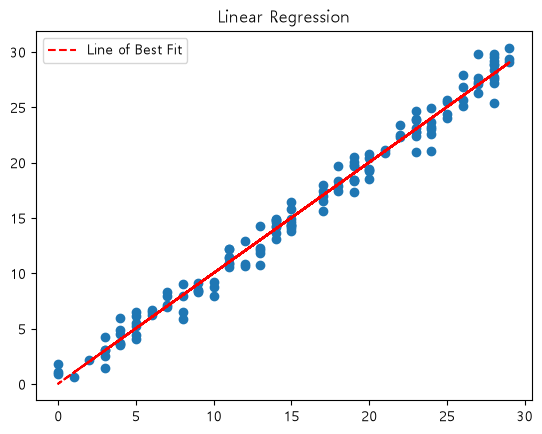

In [25]:
# code here
import matplotlib.pyplot as plt

plt.title("Linear Regression")
plt.scatter(X_train, y_train)
plt.plot(X_test, y_pred, linestyle="--", color = 'red', label="Line of Best Fit")
plt.legend()
plt.show()